In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
plt.style.use('fivethirtyeight')

In [2]:
end = datetime.now()
start = datetime(end.year-15, end.month, end.day)
crypto = 'BTC-USD'
crypto_data = yf.download(crypto, start=start, end = end)

[*********************100%***********************]  1 of 1 completed


In [3]:
crypto_data.head()

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [4]:
crypto_data.tail()

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2026-11-15,65305.062500,66055.101562,62017.882812,64128.050781,39757267458
2026-11-16,64855.843750,65604.601562,63834.671875,65305.062500,31812410118
2026-11-17,64893.945312,65365.128906,63284.457031,64855.843750,34516876177
2026-11-18,62987.265625,64928.800781,62017.378906,64893.945312,30351320839
2026-11-19,63783.011719,63985.289062,62382.484375,62987.285156,31485548544


In [5]:
crypto_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4447 entries, 2014-09-17 to 2026-11-19
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Close, BTC-USD)   4447 non-null   float64
 1   (High, BTC-USD)    4447 non-null   float64
 2   (Low, BTC-USD)     4447 non-null   float64
 3   (Open, BTC-USD)    4447 non-null   float64
 4   (Volume, BTC-USD)  4447 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 208.5 KB


In [6]:
crypto_data.describe()

Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
count,4447.000000,4447.000000,4447.000000,4447.000000,4.447000e+03
mean,30264.131748,30832.910385,29629.792158,30250.847440,2.251863e+10
std,32919.769093,33458.033293,32337.570941,32919.514794,2.263169e+10
min,178.102997,211.731003,171.509995,176.897003,5.914570e+06
25%,3676.200073,3758.401733,3620.955078,3672.393677,2.234425e+09
50%,15332.315430,15850.599609,14336.900391,15290.909180,1.862474e+10
75%,53958.300781,55404.087891,52199.929688,53893.443359,3.443055e+10
max,124752.531250,126198.070312,123196.046875,124752.140625,3.509679e+11


In [7]:
closing_price = crypto_data[['Close']]

In [8]:
closing_price['Close']

Ticker,BTC-USD
Date,
2014-09-17,457.334015
2014-09-18,424.440002
2014-09-19,394.795990
2014-09-20,408.903992
2014-09-21,398.821014
...,...
2026-11-15,65305.062500
2026-11-16,64855.843750
2026-11-17,64893.945312


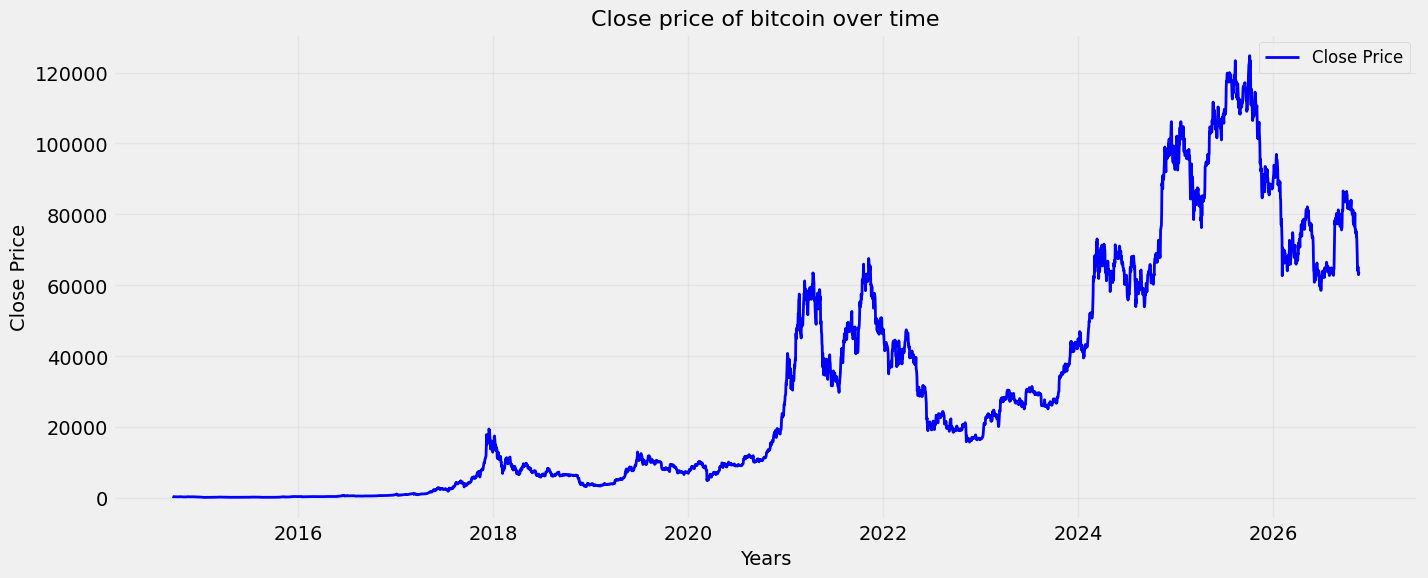

In [9]:
#Plot closing price with enchacement
plt.figure(figsize = (15, 6))
plt.plot(closing_price.index, closing_price['Close'], label = 'Close Price', color = 'blue', linewidth =2)
plt.title("Close price of bitcoin over time", fontsize = 16)
plt.xlabel("Years", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(closing_price[['Close']].dropna())

In [11]:
len(scaled_data)

4447

In [12]:
from keras.models import Sequential
from keras.layers import Dense, LSTM, Input

/Users/mohdamaanansari/Desktop/Projects/CryptoVision/ML Service/venv/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [13]:
x_data = []
y_data = []
base_days =100
for i in range(base_days, len(scaled_data)):
    x_data.append(scaled_data[i-base_days: i])
    y_data.append(scaled_data[i])
x_data = np.array(x_data)
y_data = np.array(y_data)

In [14]:
train_size = int(len(x_data) * 0.9)
x_train , y_train = x_data[:train_size], y_data[:train_size]
x_test, y_test = x_data[train_size:], y_data[train_size:]

In [15]:
model = Sequential([
    Input(shape=(x_train.shape[1], 1)),
    LSTM(128, return_sequences=True),
    LSTM(64),
    Dense(25),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 128)       │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,619 (459.45 KB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.fit(x_train, y_train, batch_size = 50, epochs = 5)

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0046
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 3.2322e-04
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 3.2156e-04
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 3.1483e-04
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 2.8891e-04


In [17]:
predictions = model.predict(x_test)
inv_predictions = scaler.inverse_transform(predictions)
inv_y_test = scaler.inverse_transform(y_test)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step


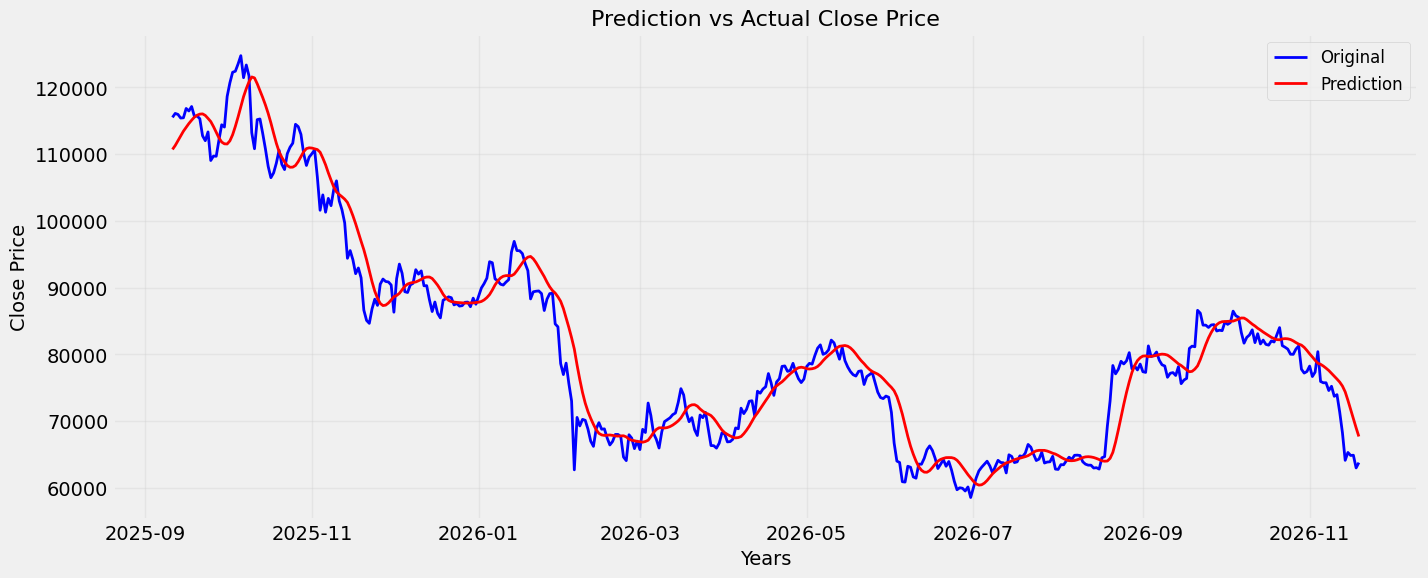

In [18]:
plotting_data = pd.DataFrame(
    {
        'Original': inv_y_test.flatten(), 
        'Prediction': inv_predictions.flatten(),
    }, index = closing_price.index[train_size + base_days:]
)

plt.figure(figsize = (15, 6))
plt.plot(plotting_data.index, plotting_data['Original'], label = 'Original', color = 'blue', linewidth =2)
plt.plot(plotting_data.index, plotting_data['Prediction'], label = 'Prediction', color = 'red',  linewidth =2)

plt.title("Prediction vs Actual Close Price", fontsize = 16)
plt.xlabel("Years", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [19]:
last_100  = scaled_data[-100:].reshape(1, -1, 1)
future_predictions=[]
for _ in range(10):
    next_days = model.predict(last_100)
    future_predictions.append(scaler.inverse_transform(next_days))
    last_100 = np.append(last_100[:, 1:, :], next_days.reshape(1, 1, -1), axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [20]:
future_predictions

[array([[66562.66]], dtype=float32),
 array([[65802.51]], dtype=float32),
 array([[65307.234]], dtype=float32),
 array([[64999.84]], dtype=float32),
 array([[64821.65]], dtype=float32),
 array([[64730.05]], dtype=float32),
 array([[64695.33]], dtype=float32),
 array([[64697.633]], dtype=float32),
 array([[64723.97]], dtype=float32),
 array([[64766.176]], dtype=float32)]

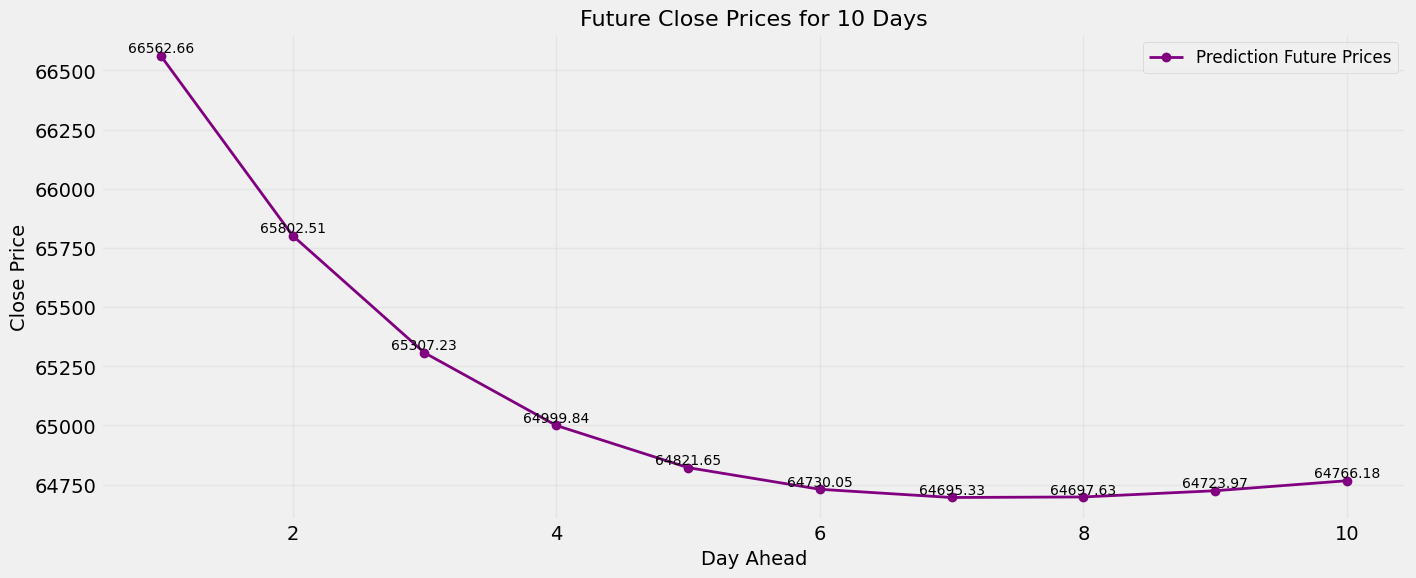

In [21]:
future_predictions = np.array(future_predictions).flatten()

plt.figure(figsize = (15, 6))
plt.plot(range(1, 11), future_predictions, marker="o" ,label = 'Prediction Future Prices', color = 'purple', linewidth =2)

for i, val in enumerate(future_predictions):
    plt.text(i+1,val,  f'{val:.2f}', fontsize = 10, ha = 'center', va = 'bottom', color='black')

plt.title("Future Close Prices for 10 Days", fontsize = 16)
plt.xlabel("Day Ahead", fontsize = 14)
plt.ylabel('Close Price', fontsize = 14)
plt.grid(alpha = 0.3)
plt.legend(fontsize = 12)
plt.show()

In [22]:
model.save("model_btc.keras")